<a href="https://colab.research.google.com/github/KrithikChidM/PrmlLab/blob/main/lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
import matplotlib.pyplot as plt

In [12]:
def uniform(a, b, n, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    samples = np.zeros(n)
    for i in range(n):
        u = rng.random()          # raw sample, uniform in [0, 1)
        samples[i] = a + (b - a) * u   # rescale u into [a, b)

    return samples


# Gaussian Distribution (polar / Marsaglia method)
def gaussian(mu, sigma, n, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    samples = np.zeros(n)
    i = 0
    while i < n:
        u1 = uniform(-1, 1, 1, rng)[0]
        u2 = uniform(-1, 1, 1, rng)[0]
        s = u1 ** 2 + u2 ** 2

        if not (0 < s < 1):
            continue             # rejected -- go throw another dart

        k = np.sqrt(-2 * np.log(s) / s)
        x = u1 * k
        y = u2 * k

        samples[i] = mu + sigma * x
        i += 1
        if i < n:
            samples[i] = mu + sigma * y
            i += 1

    return samples

In [13]:
class KMeans:
    def __init__(self, K=3):
        self.K = K
        self.centers = None

    def fit(self, X):
        rng = np.random.default_rng(42)
        indices = rng.choice(len(X), size=self.K, replace=False)
        self.centers = X[indices].astype(float)

        for _ in range(100):
            labels = self.predict(X)
            new_centers = self.centers.copy()

            for k in range(self.K):
                points = X[labels == k]
                if len(points) > 0:
                    new_centers[k] = points.mean(axis=0)

            converged = np.max(np.abs(self.centers - new_centers)) < 1e-6
            self.centers = new_centers
            if converged:
                break

        return self

    def predict(self, X):
        if self.centers is None:
            raise ValueError("Call fit() before predict().")

        labels = []
        for point in X:
            distances = [np.sum((point - center) ** 2) for center in self.centers]
            labels.append(np.argmin(distances))

        return np.array(labels, dtype=int)

### **Gaussian Mixture Data: Two Classes**

In [14]:
n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([4.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),  # bottom: full
    np.eye(2),                           # middle: isotropic
    np.diag([1.5, 0.5])                  # top: diagonal
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]
class_covariances = [covariances, covariances_2]
covariance_names = [
    ["Full (+tilt)", "Isotropic", "Diagonal"],
    ["Full (-tilt)", "Isotropic", "Full (-tilt)"]
]

In [15]:
# GMM data generation - 2 GMMs each has 3 gaussian components.

class_samples = []
class_component_labels = []

for class_index in range(2):
    rng = np.random.default_rng(42 + class_index)
    labels = np.zeros(n, dtype=int)
    for i in range(n):
        u = uniform(0, 1, 1, rng)[0]
        if u < weights[0]:
            labels[i] = 0
        elif u < weights[0] + weights[1]:
            labels[i] = 1
        else:
            labels[i] = 2

    X = np.zeros((n, 2))

    for k in range(K):
        selected = labels == k
        component_n = np.sum(selected)

        eigenvalues, eigenvectors = np.linalg.eigh(class_covariances[class_index][k])
        cov_sqrt = eigenvectors @ np.diag(np.sqrt(eigenvalues)) @ eigenvectors.T

        standard_samples = np.column_stack((
            gaussian(0, 1, component_n, rng),
            gaussian(0, 1, component_n, rng)
        ))
        X[selected] = standard_samples @ cov_sqrt.T + class_means[class_index][k]

    class_samples.append(X)
    class_component_labels.append(labels)

print([sample.shape for sample in class_samples])

[(5000, 2), (5000, 2)]


In [16]:
import pandas as pd

pd.Series(labels).value_counts()

,count
0,2498
1,1466
2,1036


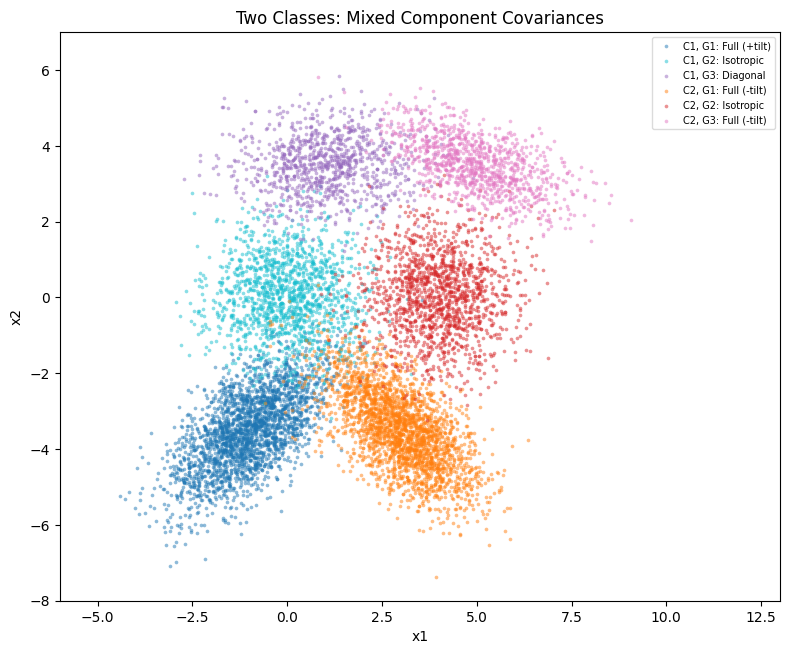

In [17]:
component_colors = [
    ["tab:blue", "tab:cyan", "tab:purple"],
    ["tab:orange", "tab:red", "tab:pink"]
]

plt.figure(figsize=(8, 7))
for class_index in range(2):
    for k in range(K):
        sample = class_samples[class_index][class_component_labels[class_index] == k]
        plt.scatter(
            sample[:, 0], sample[:, 1], s=7, alpha=0.5, linewidths=0,
            color=component_colors[class_index][k],
            label=f"C{class_index + 1}, G{k + 1}: {covariance_names[class_index][k]}"
        )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Two Classes: Mixed Component Covariances")
plt.legend(fontsize=7, framealpha=0.7)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.show()

In [18]:
# train and test split - 80% train and 20% test

train_class_samples = []
test_class_samples = []

rng = np.random.default_rng(44)
train_end = int(0.8 * n)

for samples in class_samples:
    shuffled = samples[rng.permutation(n)]
    train_class_samples.append(shuffled[:train_end])
    test_class_samples.append(shuffled[train_end:])

### **K-Means Clustering**

In [19]:
class_models = []

for class_index, samples in enumerate(train_class_samples):
    model = KMeans(K=K)
    model.fit(samples)
    class_models.append(model)
    print(f"Class {class_index + 1} centres:\n{model.centers}")

Class 1 centres:
[[-1.13320038 -3.63042138]
 [ 0.99310732  3.39538876]
 [ 0.05716161 -0.2444043 ]]
Class 2 centres:
[[ 3.90376103 -0.01883759]
 [ 3.04296659 -3.52549165]
 [ 4.95338173  3.40537357]]


### **Cluster Boundaries Within Each Class**

Learned K-means clusters and Decision Boundary between them.

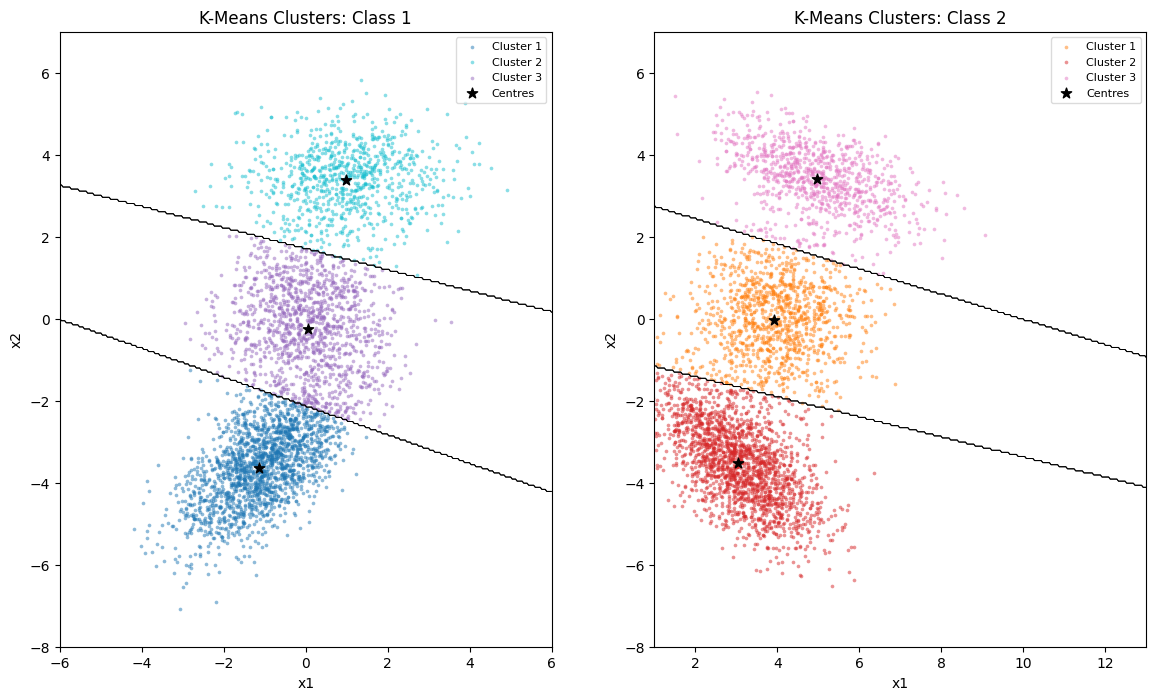

In [20]:
x_ranges = [(-6, 6), (1, 13)]
y_values = np.linspace(-8, 7, 300)

plt.figure(figsize=(12, 7))
for class_index, model in enumerate(class_models):
    samples = train_class_samples[class_index]
    labels = model.predict(samples)

    x_min, x_max = x_ranges[class_index]
    x_values = np.linspace(x_min, x_max, 300)
    x_grid, y_grid = np.meshgrid(x_values, y_values)
    grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))
    grid_labels = model.predict(grid_points).reshape(x_grid.shape)

    plt.subplot(1, 2, class_index + 1)
    for k in range(K):
        cluster = samples[labels == k]
        plt.scatter(cluster[:, 0], cluster[:, 1], s=7, alpha=0.5, linewidths=0,
                    color=component_colors[class_index][k], label=f"Cluster {k + 1}")
        plt.contour(x_grid, y_grid, grid_labels == k, levels=[0.5],
                    colors="black", linewidths=0.7)

    plt.scatter(model.centers[:, 0], model.centers[:, 1],
                marker="*", s=60, color="black", label="Centres")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"K-Means Clusters: Class {class_index + 1}")
    plt.legend(fontsize=8, framealpha=0.7)
    plt.axis("scaled")
    plt.xlim(x_min, x_max)
    plt.ylim(-8, 7)

plt.tight_layout()
plt.show()

### **Test Classification Using Distortion**

In [21]:
test_class_predictions = []

for samples in test_class_samples:
    predictions = []
    for point in samples:
        distortions = []
        for model in class_models:
            distances = np.sum((point - model.centers) ** 2, axis=1)
            distortions.append(np.min(distances))
        predictions.append(np.argmin(distortions) + 1)
    test_class_predictions.append(np.array(predictions))

In [22]:
# rows: true class, columns: predicted class
confusion_matrix = np.zeros((2, 2), dtype=int)

for true_class, predictions in enumerate(test_class_predictions):
    for predicted_class in predictions:
        confusion_matrix[true_class, predicted_class - 1] += 1

print("Confusion matrix:\n", confusion_matrix)
print("Accuracy:", np.trace(confusion_matrix) / confusion_matrix.sum())

Confusion matrix:
 [[980  20]
 [ 35 965]]
Accuracy: 0.9725


### **Decision Boundary Between the Two Classes**

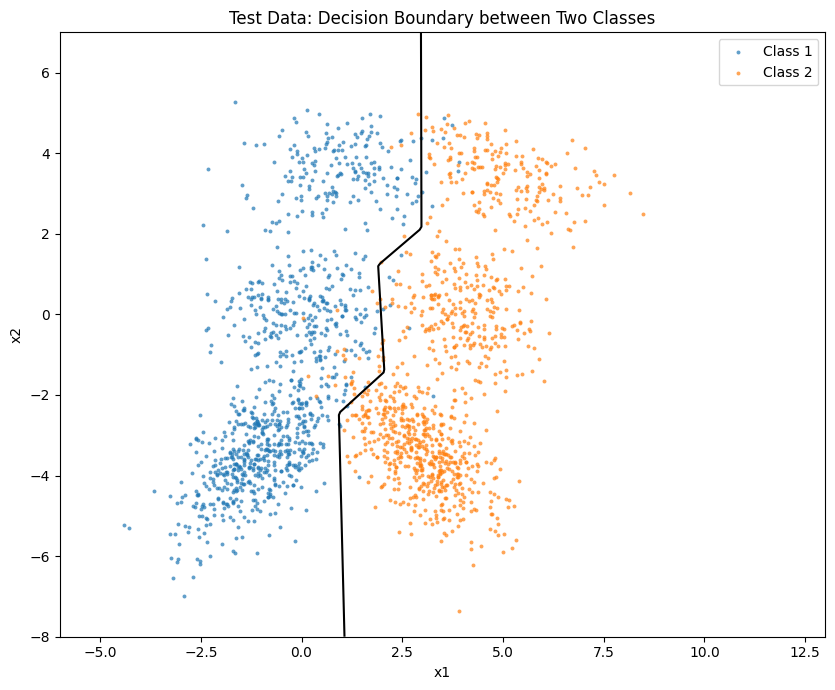

In [23]:
x_values = np.linspace(-6, 13, 200)
y_values = np.linspace(-8, 7, 200)
x_grid, y_grid = np.meshgrid(x_values, y_values)
class_distortions = []

for model in class_models:
    distances = []
    for center in model.centers:
        distances.append((x_grid - center[0]) ** 2 + (y_grid - center[1]) ** 2)
    class_distortions.append(np.min(distances, axis=0))

plt.figure(figsize=(9, 7))
for class_index, samples in enumerate(test_class_samples):
    plt.scatter(samples[:, 0], samples[:, 1], s=8, alpha=0.7, linewidths=0,
                color=component_colors[class_index][0], label=f"Class {class_index + 1}")

plt.contour(x_grid, y_grid, class_distortions[0] - class_distortions[1],
            levels=[0], colors="black")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Test Data: Decision Boundary between Two Classes")
plt.legend(fontsize=10)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.show()